# 01 — Data audit, product selection and EDA

**Project:** Demand Forecasting for Supply Chain Inventory Optimization (Walmart M5, store CA_1)

This notebook covers milestones M1–M2: it audits the processed dataset, explains how the 8 study products were chosen, and explores their demand patterns.

**Leakage rule:** everything here uses data up to **d_1800 (2016-01-02)**, the earliest forecast origin. No figure or table looks at any test window, so nothing learned here can bias model evaluation later.

Logic lives in `src/optichain/`; this notebook only calls it and interprets results. All figures are also produced by `scripts/run_eda.py`.

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from optichain import eda
from optichain import plots as P
from optichain.config import PROJECT_ROOT, load_config
from optichain.data_pipeline import get_series, validate_long, audit_table

P.apply_style()
pd.set_option("display.precision", 3)
cfg = load_config()
END_D = min(cfg.forecast.origins)   # 1800
WINDOW = cfg.forecast.fit_window_days  # 730
ITEMS = cfg.series.items
print("EDA cutoff: d_%d | window: %d days | items: %d" % (END_D, WINDOW, len(ITEMS)))

EDA cutoff: d_1800 | window: 730 days | items: 8


## 1. Data audit

`scripts/build_dataset.py` filtered the M5 sales file to store CA_1, reshaped it from wide (one column per day) to long (one row per item-day), and joined the calendar and weekly prices. Validation checks run inside the pipeline; they are re-run here.

In [2]:
long_all = pd.read_parquet(cfg.data.processed_dir / "ca_1_long.parquet")
validate_long(long_all, n_series=long_all["item_id"].nunique(), max_day=cfg.data.max_day)
print(f"rows: {len(long_all):,} | items: {long_all['item_id'].nunique()} | days: {long_all['d'].nunique()}")
print(f"dates: {long_all['date'].min().date()} -> {long_all['date'].max().date()}")
print("validation: passed (unique keys, non-negative sales, contiguous dates, price after launch)")

rows: 5,832,737 | items: 3049 | days: 1913
dates: 2011-01-29 -> 2016-04-24
validation: passed (unique keys, non-negative sales, contiguous dates, price after launch)


In [3]:
audit = pd.read_csv(PROJECT_ROOT / "reports/metrics/ca_1_data_audit.csv", parse_dates=["launch_date"])
summary = pd.Series({
    "items": len(audit),
    "items launched after d_1": int((audit["launch_d"] > 1).sum()),
    "pre-launch share of all rows": f"{(~long_all['launched']).mean():.1%}",
    "sales recorded before launch": int(long_all.loc[~long_all['launched'], 'sales'].sum()),
    "post-launch days with filled-in price": int(audit["price_imputed_days"].sum()),
    "median zero-sales share (post-launch)": f"{audit['zero_share'].median():.1%}",
})
display(summary.to_frame("value"))
display(audit.groupby("cat_id")[["mean_sales", "zero_share"]].median().rename(columns=lambda c: "median " + c))

,value
items,3049
items launched after d_1,1845
pre-launch share of all rows,19.4%
sales recorded before launch,0
post-launch days with filled-in price,0
median zero-sales share (post-launch),58.1%


,median mean_sales,median zero_share
cat_id,,
FOODS,1.112,0.496
HOBBIES,0.412,0.730
HOUSEHOLD,0.525,0.651


**Findings**

- 1,845 of 3,049 items were launched after the first day. Their earlier rows are zeros only because the product did not exist yet, so each series starts at its first priced week. No sales occur before launch, which confirms this rule.
- No price gaps appear after launch, so no prices had to be filled in.
- A typical CA_1 item sells nothing on most days: the median item has zero sales on 58% of its days since launch. Zero-heavy demand is the normal case in this store, not an exception.

In [4]:
del long_all  # free memory; the rest of the notebook uses only the 8 selected series
long = pd.read_parquet(cfg.data.processed_dir / "selected_series.parquet")

## 2. Product selection by demand pattern

Items are classified with the Syntetos–Boylan scheme on the 730 days before d_1800:

- **ADI** (average inter-demand interval) = days ÷ days with a sale. A value of 1 means something sells every day.
- **CV²** = squared coefficient of variation of the *non-zero* sales sizes.

| | CV² < 0.49 | CV² ≥ 0.49 |
|---|---|---|
| **ADI < 1.32** | smooth | erratic |
| **ADI ≥ 1.32** | intermittent | lumpy |

Eligibility rules: at least 730 days of history since launch; at least one sale in the last 90 days, so discontinued items are excluded; and **no run of more than 28 consecutive zero-sales days**. At these sales rates a month-long run of zeros is almost always a stockout or the item leaving the shelf, not genuine zero demand. Including such items would mix supply problems into the forecasting comparison.

In [5]:
classes = pd.read_csv(PROJECT_ROOT / "reports/metrics/ca_1_demand_classes.csv")
item_class = classes.set_index("item_id")["demand_class"]
counts = pd.crosstab(classes["demand_class"], classes["cat_id"], margins=True).reindex(P.CLASS_ORDER + ["All"])
display(counts)
long_runs = (classes["max_zero_run"] > 28).groupby(classes["demand_class"]).mean().reindex(P.CLASS_ORDER)
display(long_runs.to_frame("share with a zero run > 28 days").style.format("{:.0%}"))

cat_id,FOODS,HOBBIES,HOUSEHOLD,All
demand_class,,,,
smooth,164,8,72,244
erratic,42,19,7,68
intermittent,696,380,713,1789
lumpy,269,71,54,394
All,1171,478,846,2495


,share with a zero run > 28 days
demand_class,
smooth,13%
erratic,19%
intermittent,66%
lumpy,66%


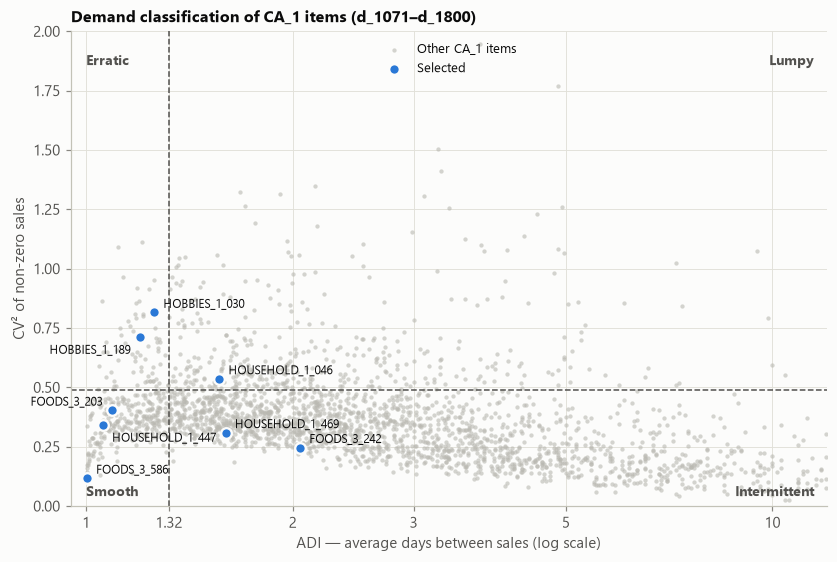

In [6]:
fig = eda.fig_adi_cv2(classes, ITEMS)

In [7]:
selected = pd.read_csv(PROJECT_ROOT / "reports/metrics/selected_items.csv")
display(selected[["item_id", "cat_id", "demand_class", "volume_quantile", "mean", "zero_share", "adi", "cv2", "max_zero_run", "mean_price"]])

,item_id,cat_id,demand_class,volume_quantile,mean,zero_share,adi,cv2,max_zero_run,mean_price
0,FOODS_3_586,FOODS,smooth,1.00,44.919,0.003,1.003,0.117,1,1.652
1,HOUSEHOLD_1_447,HOUSEHOLD,smooth,0.75,6.232,0.055,1.058,0.342,7,0.979
2,FOODS_3_203,FOODS,smooth,0.50,3.518,0.082,1.090,0.403,3,4.480
3,HOBBIES_1_189,HOBBIES,erratic,0.75,7.301,0.164,1.197,0.712,8,0.467
4,HOBBIES_1_030,HOBBIES,erratic,0.50,4.819,0.204,1.256,0.816,5,0.700
5,HOUSEHOLD_1_469,HOUSEHOLD,intermittent,0.75,1.118,0.374,1.597,0.309,14,17.970
6,FOODS_3_242,FOODS,intermittent,0.50,0.749,0.512,2.051,0.246,25,9.796
7,HOUSEHOLD_1_046,HOUSEHOLD,lumpy,0.50,1.297,0.360,1.563,0.536,6,3.780


**Findings**

- Of 2,495 eligible items, 72% are intermittent and only 10% are smooth. The classical ARIMA setting is the minority case in this store.
- About two-thirds of intermittent and lumpy items, and 13% of smooth ones, have a run of more than 28 days with no sales. Censored demand (sales capped by stock outages) is therefore common in M5. This is an important limitation for the inventory simulation, which treats observed sales as demand.
- Selection is deterministic. Within each class, the pick is the item closest to a target volume quantile, preferring categories not yet represented. The highest-volume smooth item, **FOODS_3_586** (about 45 units a day), is included on purpose as the main demonstration series.
- The final set has 3 smooth, 2 erratic, 2 intermittent and 1 lumpy item, covering FOODS, HOUSEHOLD and HOBBIES.

## 3. Overview of the selected series

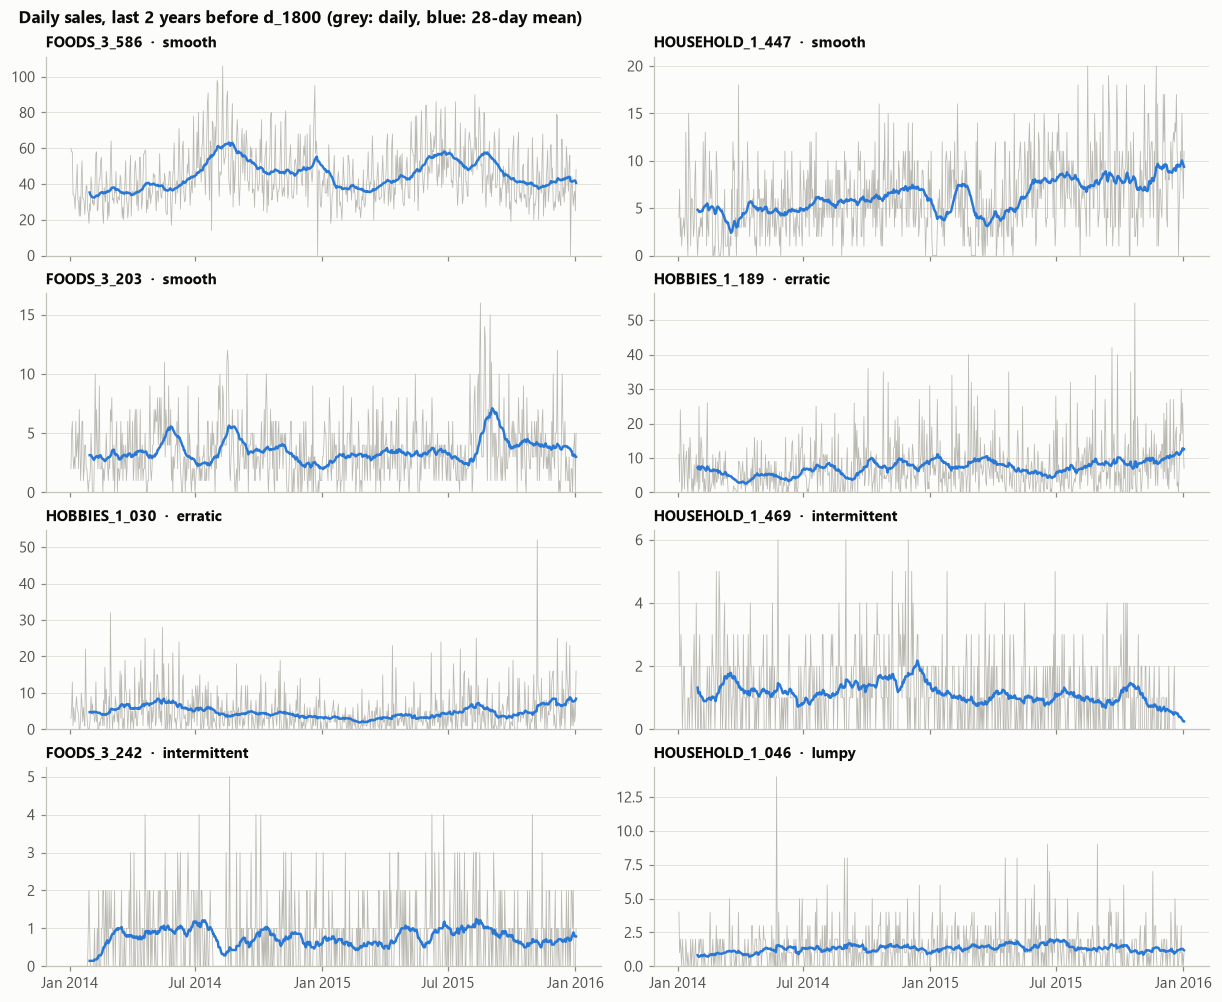

In [8]:
fig = eda.fig_small_multiples(long, ITEMS, item_class, END_D, WINDOW)

- **FOODS_3_586** has a strong, stable level with a clear summer rise each year, a good candidate for ETS and SARIMA.
- **HOUSEHOLD_1_447** trends upward (about 5 units a day in 2014, about 9 by late 2015), so level changes matter and a model that cannot adapt its level will lag.
- **FOODS_3_203** shows short promotion-like bursts (for example around Oct 2015) over a low base.
- The erratic **HOBBIES** items have occasional large spikes (up to 50 units against a mean of 5–7). These spikes drive RMSE and are a natural place to check for ARCH effects.
- **HOUSEHOLD_1_469** declines in the last weeks before d_1800. Watch it in the test windows: this may be the start of a stockout or a delisting.
- The intermittent and lumpy items mostly sell 0–2 units a day with a fairly flat mean, which is where Croston-type methods are expected to compete.

## 4. Demand variability

In [9]:
var = eda.variability_table(long, ITEMS, END_D, WINDOW)
display(var[["demand_class", "mean", "median", "std", "cv", "zero_share", "adi", "cv2", "max_zero_run", "mean_price"]])

,demand_class,mean,median,std,cv,zero_share,adi,cv2,max_zero_run,mean_price
item_id,,,,,,,,,,
FOODS_3_586,smooth,44.919,42.0,15.558,0.346,0.003,1.003,0.117,1,1.652
HOUSEHOLD_1_447,smooth,6.232,6.0,4.037,0.648,0.055,1.058,0.342,7,0.979
FOODS_3_203,smooth,3.518,3.0,2.559,0.727,0.082,1.090,0.403,3,4.480
HOBBIES_1_189,erratic,7.301,5.0,7.478,1.024,0.164,1.197,0.712,8,0.467
HOBBIES_1_030,erratic,4.819,3.0,5.455,1.132,0.204,1.256,0.816,5,0.700
HOUSEHOLD_1_469,intermittent,1.118,1.0,1.168,1.045,0.374,1.597,0.309,14,17.970
FOODS_3_242,intermittent,0.749,0.0,0.935,1.248,0.512,2.051,0.246,25,9.796
HOUSEHOLD_1_046,lumpy,1.297,1.0,1.535,1.184,0.360,1.563,0.536,6,3.780


- The coefficient of variation rises from 0.35 for FOODS_3_586 to about 1.0–1.25 for the erratic, intermittent and lumpy items. Daily noise is as large as the mean for most of the set.
- Zero-sales share ranges from 0.3% to 51%. This is why **MAPE cannot be used** for model ranking (it divides by actual sales, which are often zero), and why the evaluation relies on MAE, RMSE and RMSSE.
- FOODS_3_586's longest zero run is a single day, the Christmas closure.

## 5. Weekly seasonality

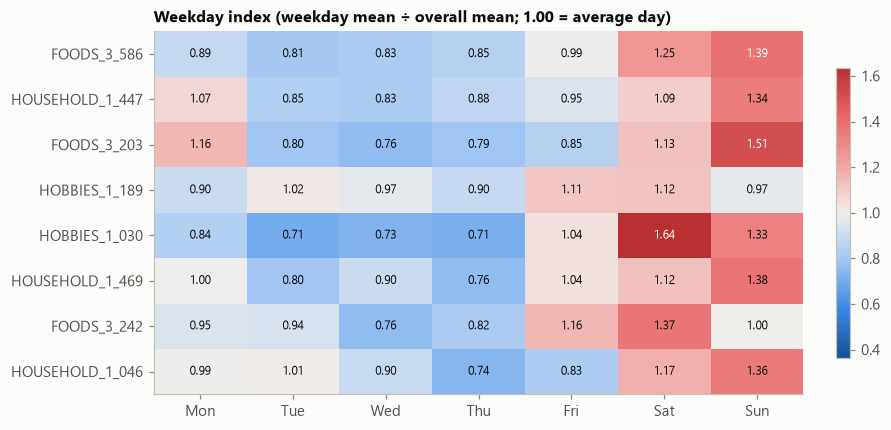

In [10]:
wd = eda.weekday_index_table(long, ITEMS, END_D, WINDOW)
fig = eda.fig_weekday_heatmap(wd)

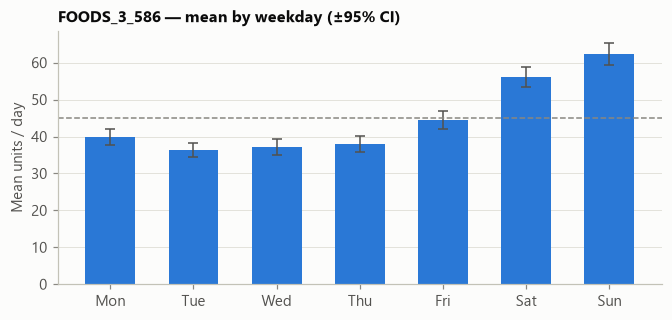

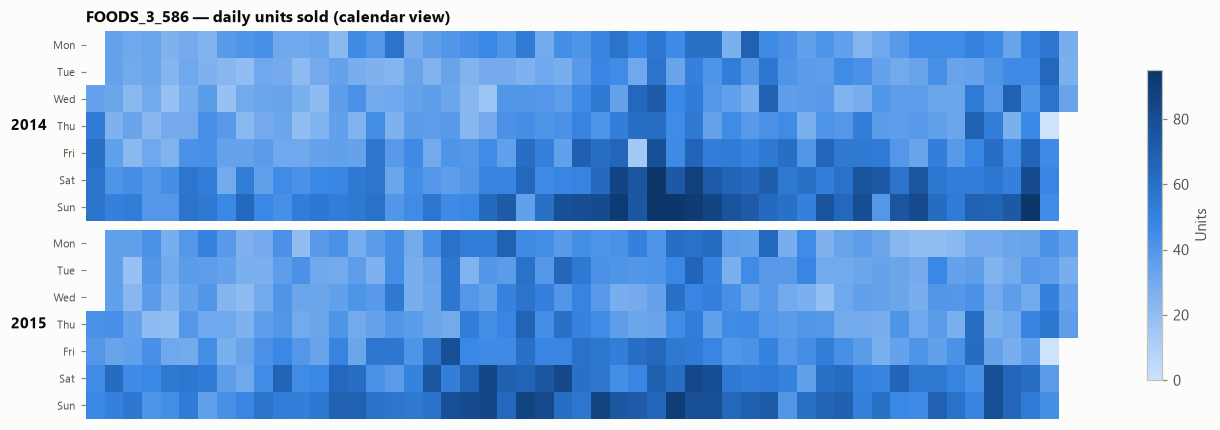

In [11]:
s = get_series(long, ITEMS[0], END_D)
fig = eda.fig_weekday(s.iloc[-WINDOW:], f"{ITEMS[0]} — mean by weekday (±95% CI)")
fig = eda.fig_calendar_heatmap(s, f"{ITEMS[0]} — daily units sold (calendar view)", [2014, 2015])

- Almost every series peaks at the **weekend**: Saturday and Sunday are 1.1–1.6 times an average day, and Tuesday to Thursday are typically 0.7–0.9 times. The confidence intervals for FOODS_3_586 show this is well beyond noise.
- HOBBIES_1_189 is the exception, with a nearly flat weekly profile.
- **Implication:** a 7-day seasonal period is justified for daily models (seasonal naive, ETS with s=7, SARIMA with s=7). Seasonal naive is expected to be a strong baseline.
- The calendar heatmap shows the weekend bands, the summer high season, and the pale Christmas Day cell (store closed).

## 6. Events, SNAP and price

Event days are compared with non-event days in the 730-day window. Christmas is excluded and treated as a store closure: every M5 store sells zero units on 25 December each year.

In [12]:
cal = eda.calendar_effects(long, ITEMS, END_D, WINDOW)
display(cal)
display(eda.event_type_effects(long, ITEMS[0], END_D))
zero_days = long[(long["item_id"] == ITEMS[0]) & (long["d"] <= END_D) & (long["sales"] == 0)][["date", "event_name_1"]]
display(zero_days)

,cat_id,event_days,mean_event,mean_no_event,event_ratio,snap_ratio
item_id,,,,,,
FOODS_3_586,FOODS,56,46.143,44.951,1.027,1.038
HOUSEHOLD_1_447,HOUSEHOLD,56,5.839,6.283,0.929,0.995
FOODS_3_203,FOODS,56,2.946,3.576,0.824,1.137
HOBBIES_1_189,HOBBIES,56,6.339,7.403,0.856,1.060
HOBBIES_1_030,HOBBIES,56,5.250,4.798,1.094,0.994
HOUSEHOLD_1_469,HOUSEHOLD,56,1.179,1.116,1.056,0.967
FOODS_3_242,FOODS,56,0.804,0.747,1.076,1.031
HOUSEHOLD_1_046,HOUSEHOLD,56,1.393,1.293,1.077,1.004


,mean,size,ratio_vs_no_event
event_type_1,,,
Sporting,45.200,15,0.973
Religious,46.333,48,0.997
none,46.450,1656,1.000
National,50.523,44,1.088
Cultural,52.625,32,1.133


,date,event_name_1
4156,2011-12-25,Christmas
4209,2012-02-16,none
4210,2012-02-17,none
4522,2012-12-25,Christmas
4887,2013-12-25,Christmas
5252,2014-12-25,Christmas
5617,2015-12-25,Christmas


- **Events** have a small and inconsistent effect at the item level: the ratio of event-day to non-event-day sales is 0.82–1.09 with only 56 event days. By event type, FOODS_3_586 sells about 13% more on Cultural events and 9% more on National holidays, and nothing extra on Sporting or Religious events.
- **SNAP** days (US food-assistance payment days) lift FOODS_3_203 by 14% and the other FOODS items by 3–4%. HOUSEHOLD and HOBBIES show no effect, as expected since SNAP benefits apply to food.
- **Christmas closure** is the only systematic calendar effect, and none of the forecast windows (January–April) contain it. FOODS_3_586's other zero days (16–17 Feb 2012) are not holidays and are most likely a short stockout.
- These are associations, not causal effects. The ratios also mix in weekday composition, since events fall on different weekdays.
- **Implication:** exogenous event regressors are not a priority for the univariate models. They remain an option for the stretch goal of a machine-learning model that uses calendar features.

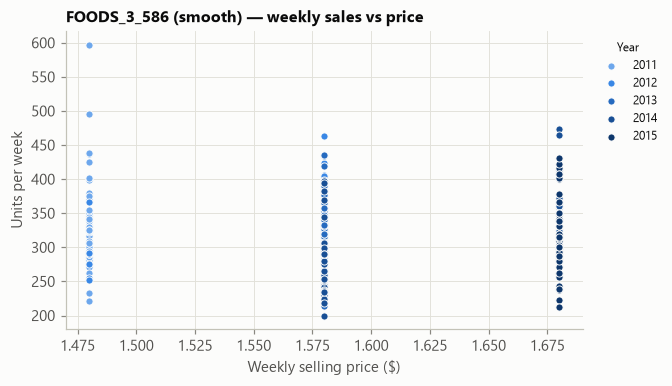

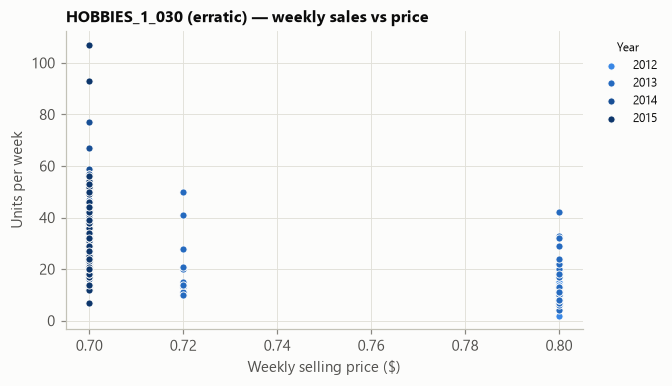

In [13]:
for item in ["FOODS_3_586", "HOBBIES_1_030"]:
    wk = eda.weekly_price_sales(long, item, END_D)
    fig = eda.fig_price_scatter(wk, f"{item} ({item_class[item]}) — weekly sales vs price")

- Prices change rarely: a handful of distinct levels over five years, usually stepping in a single direction.
- Each price level therefore mostly corresponds to a **time period**. HOBBIES_1_030's higher sales at \$0.70 come from 2014–15, when demand was also higher for other reasons. Price and time are confounded, so no price-elasticity conclusion is drawn from these plots.

## 7. Per-item figures

Daily, weekly, distribution, weekday and price figures for every selected item are saved in `reports/figures/eda/<item_id>/`. Two contrasting distributions are shown here.

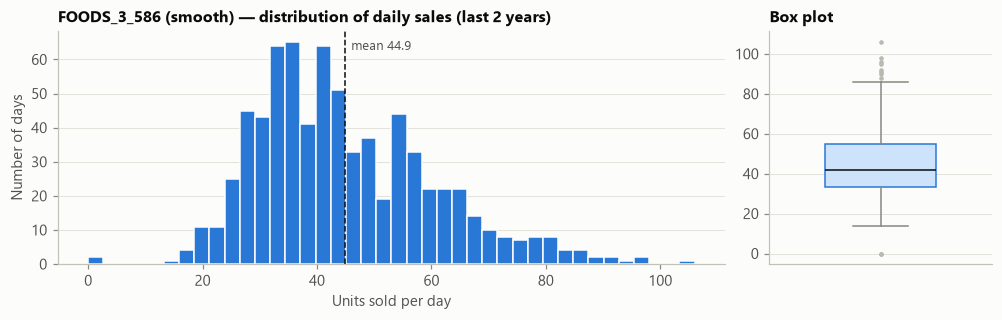

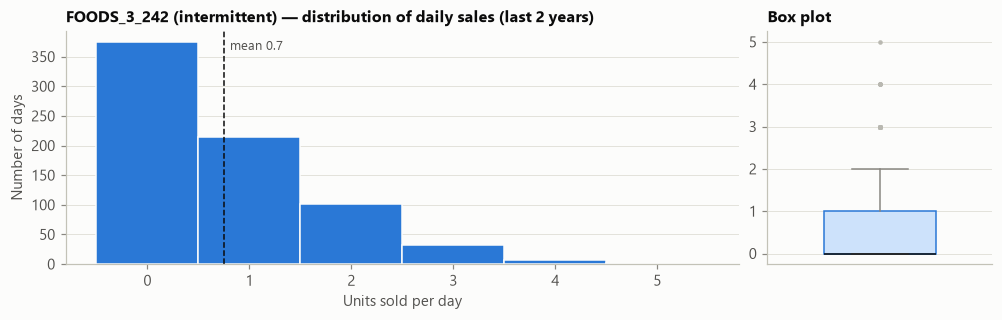

In [14]:
for item in ["FOODS_3_586", "FOODS_3_242"]:
    s = get_series(long, item, END_D).iloc[-WINDOW:]
    fig = eda.fig_distribution(s, f"{item} ({item_class[item]}) — distribution of daily sales (last 2 years)")

## 8. Summary and implications for modelling

| Finding | Consequence for M4–M7 |
|---|---|
| Strong weekend peak in 7 of 8 series | Use s = 7; seasonal naive is the benchmark to beat |
| Zero share 0.3%–51%; censored stockout runs common | Rank models by RMSSE/MAE, never MAPE; state the censored-demand limitation in the inventory results |
| Level shifts and trend (HOUSEHOLD_1_447) | Compare trend and damped-trend ETS; consider d = 1 if the ADF and KPSS tests support it |
| Large spikes in the erratic HOBBIES items | Candidates for ARCH-LM testing |
| Event effects small and inconsistent; SNAP helps FOODS only | Keep univariate models; leave regressors to the stretch ML model |
| Christmas = store closure | Outside all forecast windows; no special handling needed for the backtests |
| Intermittent and lumpy items sell 0–2 units a day | Include Croston/SBA; expect ARIMA to add little over simple benchmarks |